# Branch length estimation

Solvers such as {func}`cassiopeia.solver.nj` return the topology of a tree, but not when each division
happened. {func}`cassiopeia.tl.estimate_branch_lengths` estimates these times from the edits with
[ConvexML](https://github.com/songlab-cal/ConvexML), a maximum likelihood method for irreversible edits
that accounts for missing data. Edits accumulate over time, so a branch along which many sites were edited
is likely long.

ConvexML needs to know which edits happened on which branch, so it uses the states of the ancestral
nodes from {func}`cassiopeia.tl.ancestral_characters`. In this tutorial we use simulations to show that
the choice of ancestral reconstruction method matters as soon as the data contain a few miscalled
sites, and benchmark the accuracy of branch length estimation.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pycea as py
import seaborn as sns
from joblib import Parallel, delayed

import cassiopeia as cas

## Simulate data

We simulate a tree of 500 cells with {func}`cassiopeia.sim.birth_death_process` and scale its node
times from 0 (root) to 1 (leaves) with {func}`cassiopeia.tl.rescale_node_times`, which is the scale of
the estimated times. We then simulate Cas9 lineage tracing data with 30 target sites, of which about
60% are edited by the end, and remove 10% of the sites at random as missing data. See the
[benchmarking pipeline](benchmark.ipynb) for an introduction to these functions.

In [2]:
def simulate(random_seed, noise=0.0):
    """Simulate a tree with lineage tracing data, missing data and noise."""
    tdata = cas.sim.birth_death_process(num_extant=500, random_seed=random_seed)
    cas.tl.rescale_node_times(tdata)
    cas.sim.stochastic_tracing(tdata, mutation_rate=1.0, random_seed=random_seed)
    cas.sim.missing_data(tdata, stochastic_rate=0.1, random_seed=random_seed)
    if noise:
        cas.sim.noise(tdata, error_rate=noise, priors=True, random_seed=random_seed)
    return tdata


tdata = simulate(random_seed=0)
tdata

TreeData object with n_obs × n_vars = 500 × 0
    obs: 'tree', 'birth_scale', 'time'
    uns: 'cassette_size', 'unmodified_state', 'missing_state', 'priors', 'characters_colors'
    obsm: 'characters'
    obst: 'simulated'

The simulated tree and character matrix, plotted with {func}`pycea.pl.tree`. It uses the colors that
`stochastic_tracing` stores in `tdata.uns["characters_colors"]`: each indel has its own color,
unedited sites are grey and missing sites are white.

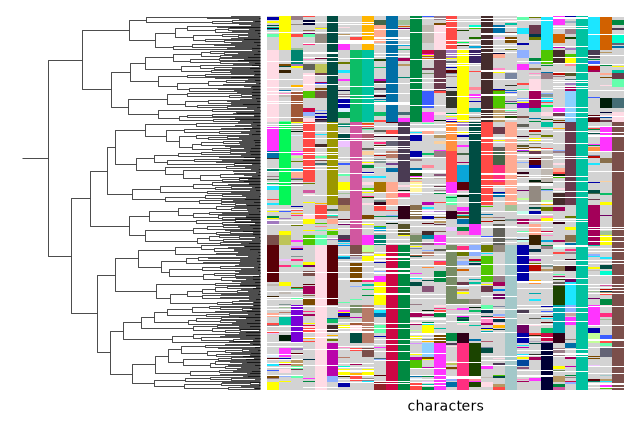

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
py.pl.tree(tdata, depth_key="time", keys="characters", legend=False, ax=ax);

## Estimate branch lengths on the true topology

To separate branch length estimation from errors in the topology, we start from the true topology. We
copy the simulated tree without its node attributes, infer the ancestral states, and estimate the branch
lengths:

In [4]:
tdata.obst["estimated"] = nx.DiGraph(tdata.obst["simulated"].edges)
cas.tl.ancestral_characters(tdata, tree_key="estimated", method="sankoff")
cas.tl.estimate_branch_lengths(tdata, tree_key="estimated")
tdata.uns["branch_lengths"]

{'method': 'convexml',
 'mutation_rate': 0.9097728352905384,
 'log_likelihood': -3398.7362182337815,
 'penalized_log_likelihood': -3698.2156179057665,
 'solver': 'CLARABEL'}

The estimated times are stored in the `time` attribute of each node, and the branch lengths in the
`length` attribute of each edge. Since both trees have the same nodes, we can compare the times
directly:

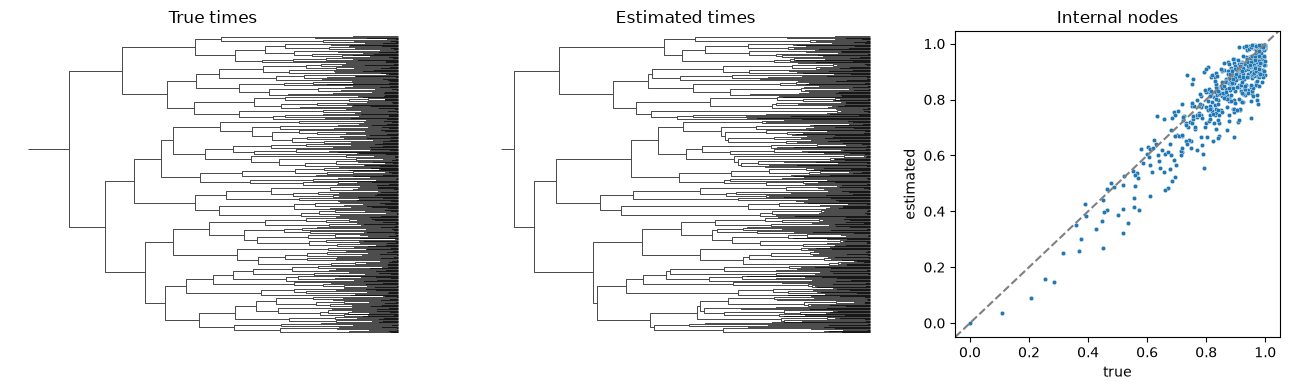

In [5]:
def node_times(tdata, key):
    """Times of the internal nodes of `obst[key]`."""
    tree = tdata.obst[key]
    return pd.Series(dict(tree.nodes(data="time")))[[n for n in tree if tree.out_degree(n) > 0]]


times = pd.DataFrame(
    {"true": node_times(tdata, "simulated"), "estimated": node_times(tdata, "estimated")}
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1, 0.8]})
py.pl.tree(tdata, tree="simulated", depth_key="time", ax=axes[0])
py.pl.tree(tdata, tree="estimated", depth_key="time", ax=axes[1])
sns.scatterplot(times, x="true", y="estimated", s=10, ax=axes[2])
axes[2].axline((0, 0), slope=1, color="grey", linestyle="--")
for ax, title in zip(axes, ["True times", "Estimated times", "Internal nodes"], strict=True):
    ax.set_title(title)
plt.tight_layout()

The estimates follow the true times closely. Deep nodes are the hardest to place, since few edits
occurred in the short branches near the root.

## Ancestral states matter

Real character matrices contain miscalled sites, from sequencing errors or ambient RNA. We add noise to
1% of the entries with {func}`cassiopeia.sim.noise` and infer ancestral states on the true topology
with two methods:

* `"camin_sokal"`: edits are irreversible, so a node carries only the edits shared by all of its
  descendants (with data at that site).
* `"sankoff"`: weighted Sankoff parsimony, where gaining an edit costs 1 and changing an existing edit
  costs `reedit_cost` (2.5).

In [6]:
noisy = simulate(random_seed=0, noise=0.01)
for method in ["camin_sokal", "sankoff"]:
    noisy.obst[method] = nx.DiGraph(noisy.obst["simulated"].edges)
    cas.tl.ancestral_characters(noisy, tree_key=method, method=method)

The simulated tree stores the true states of every node, so we can count the internal nodes that each
method gets wrong:

In [7]:
true = noisy.obst["simulated"]
truth = dict(true.nodes(data="characters"))
internal = [n for n in true if true.out_degree(n) > 0]


def wrong(key, site):
    """Internal nodes whose state at `site` differs from the true state."""
    tree = noisy.obst[key]
    return [n for n in internal if tree.nodes[n]["characters"][site] != truth[n][site]]


methods = ["camin_sokal", "sankoff"]
errors = pd.DataFrame({key: [len(wrong(key, site)) for site in range(30)] for key in methods})
errors.sum()

camin_sokal    510
sankoff        248
dtype: int64

Let's look at the site where Camin-Sokal makes the most mistakes, in the clade of cells that inherited
an edit there. We find the highest node with a wrong state that truly carries an edit, and walk up the
true tree to the node where the edit was gained:

In [8]:
site = errors["camin_sokal"].idxmax()
edited = [n for n in wrong("camin_sokal", site) if truth[n][site] not in ("*", "-")]
node = min(edited, key=lambda n: true.nodes[n]["time"])
edit = truth[node][site]
while truth[next(true.predecessors(node))][site] == edit:
    node = next(true.predecessors(node))
clade = noisy[[n for n in nx.descendants(true, node) if true.out_degree(n) == 0]].copy()
print(f"Site {site}, edit {edit}: clade of {clade.n_obs} cells")

Site 17, edit 13: clade of 111 cells


We plot the state of this site at every internal node of the clade with {func}`pycea.pl.nodes`, and in
each cell with {func}`pycea.pl.annotation`:

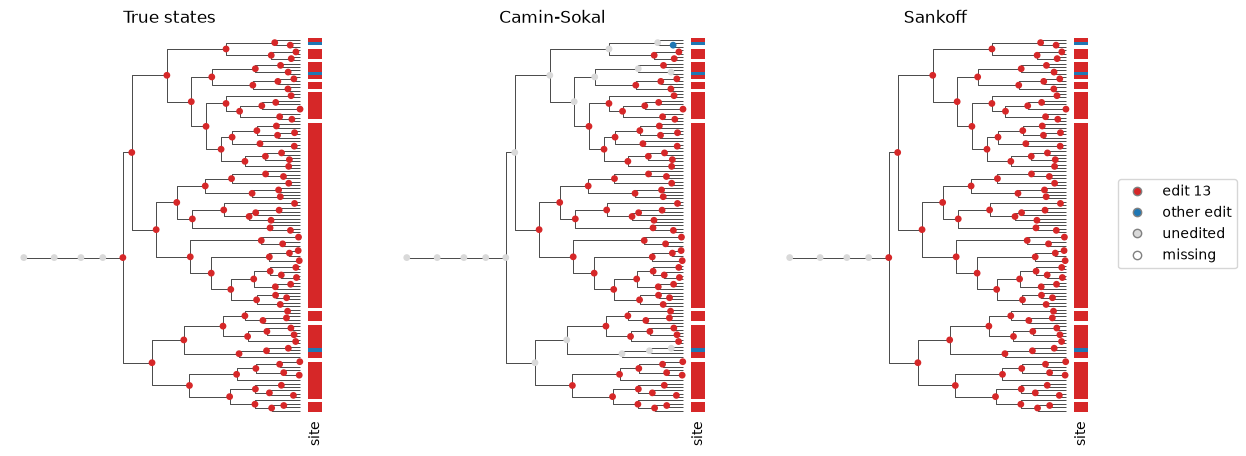

In [9]:
def label(state):
    """Label a state as the clade's edit, another edit, unedited or missing."""
    return {edit: f"edit {edit}", "*": "unedited", "-": "missing"}.get(state, "other edit")


palette = {
    f"edit {edit}": "tab:red",
    "other edit": "tab:blue",
    "unedited": "#d9d9d9",
    "missing": "white",
}
titles = {"simulated": "True states", "camin_sokal": "Camin-Sokal", "sankoff": "Sankoff"}
clade.obs["site"] = clade.obsm["characters"].iloc[:, site].map(label)
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, key in zip(axes, ["simulated", "camin_sokal", "sankoff"], strict=True):
    tree = clade.obst[key]
    states = {n: label(chars[site]) for n, chars in tree.nodes(data="characters")}
    nx.set_node_attributes(tree, states, "site")
    nx.set_node_attributes(tree, dict(true.nodes(data="time")), "true_time")
    py.pl.branches(clade, tree=key, depth_key="true_time", ax=ax)
    py.pl.nodes(clade, tree=key, color="site", palette=palette, size=15, legend=False, ax=ax)
    py.pl.annotation(clade, keys="site", palette=palette, legend=False, ax=ax)
    ax.set_title(titles[key])
handles = [
    plt.Line2D([], [], marker="o", ls="", color=c, mec="grey", label=k) for k, c in palette.items()
]
axes[2].legend(handles=handles, loc="center left", bbox_to_anchor=(1.05, 0.5));

All cells of this clade inherited the edit, but a few were miscalled with another state. Camin-Sokal
does not allow an edit to change, so every ancestor of a miscalled cell becomes unedited, and the edit is
instead gained independently on many branches below them. Sankoff pays for one change on each miscalled
cell and keeps the edit on the clade's ancestors. Over all sites, Sankoff assigns less than half as many
wrong states.

These mistakes distort the branch lengths: the misplaced edits stretch the branches near the leaves and
shorten the deep ones.

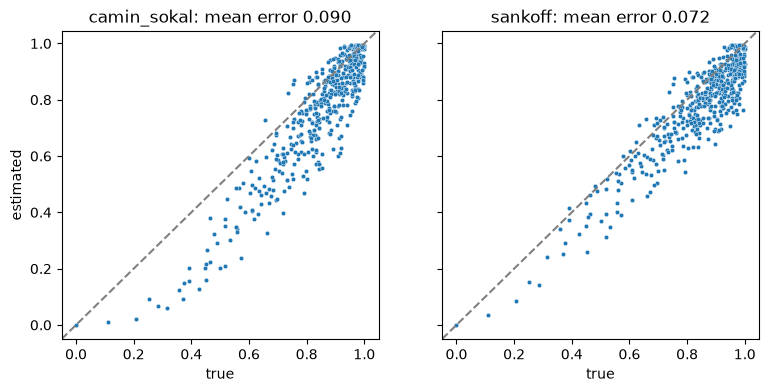

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, method in zip(axes, ["camin_sokal", "sankoff"], strict=True):
    cas.tl.estimate_branch_lengths(noisy, tree_key=method)
    times = pd.DataFrame(
        {"true": node_times(noisy, "simulated"), "estimated": node_times(noisy, method)}
    )
    error = (times["estimated"] - times["true"]).abs().mean()
    sns.scatterplot(times, x="true", y="estimated", s=10, ax=ax)
    ax.axline((0, 0), slope=1, color="grey", linestyle="--")
    ax.set_title(f"{method}: mean error {error:.3f}")

## Benchmark

We now measure the accuracy of branch length estimation over several simulations, noise levels and
ancestral reconstruction methods. Besides Camin-Sokal and Sankoff, we include `"conservative"`, which
sets edits whose placement is ambiguous to missing (as in ConvexML). We use both the true topology and a
topology reconstructed with {func}`cassiopeia.solver.nj` (followed by
{func}`cassiopeia.tl.collapse_edges`).

Since a reconstructed tree has different internal nodes, we measure accuracy on pairs of cells: the
time of the most recent common ancestor of two cells, computed for every pair with
{func}`pycea.tl.tree_distance` (`metric="lca"`), should match its true value.

In [11]:
def lca_error(tdata, key):
    """Mean absolute error of the LCA times of all pairs of cells."""
    kwargs = {"depth_key": "time", "metric": "lca", "copy": True}
    true = py.tl.tree_distance(tdata, tree="simulated", **kwargs)
    estimated = py.tl.tree_distance(tdata, tree=key, **kwargs)
    return np.abs(true - estimated).mean()


def benchmark(random_seed, noise):
    """Estimate branch lengths for every topology and method and measure their error."""
    tdata = simulate(random_seed, noise)
    cas.solver.nj(tdata, key_added="nj_topology")
    tdata.obst["true_topology"] = nx.DiGraph(tdata.obst["simulated"].edges)
    results = []
    for topology in ["true_topology", "nj_topology"]:
        for method in ["camin_sokal", "conservative", "sankoff"]:
            tdata.obst["estimated"] = tdata.obst[topology].copy()
            cas.tl.ancestral_characters(tdata, tree_key="estimated", method=method)
            if topology == "nj_topology":
                cas.tl.collapse_edges(tdata, tree_key="estimated")
            cas.tl.estimate_branch_lengths(tdata, tree_key="estimated")
            error = lca_error(tdata, "estimated")
            results.append({"topology": topology, "method": method, "noise": noise, "error": error})
    return results

We run 5 simulations for each noise level in parallel with [joblib](https://joblib.readthedocs.io):

In [12]:
runs = [(seed, noise) for seed in range(5) for noise in [0, 0.01, 0.02, 0.05]]
results = Parallel(n_jobs=8)(delayed(benchmark)(seed, noise) for seed, noise in runs)
results = pd.DataFrame([row for rows in results for row in rows])
results.groupby(["topology", "noise", "method"])["error"].mean().unstack().round(3)

method               camin_sokal  conservative  sankoff
topology      noise                                    
nj_topology   0.00         0.117         0.117    0.117
              0.01         0.179         0.179    0.117
              0.02         0.209         0.209    0.118
              0.05         0.228         0.228    0.113
true_topology 0.00         0.053         0.053    0.052
              0.01         0.169         0.169    0.050
              0.02         0.193         0.193    0.049
              0.05         0.204         0.204    0.051

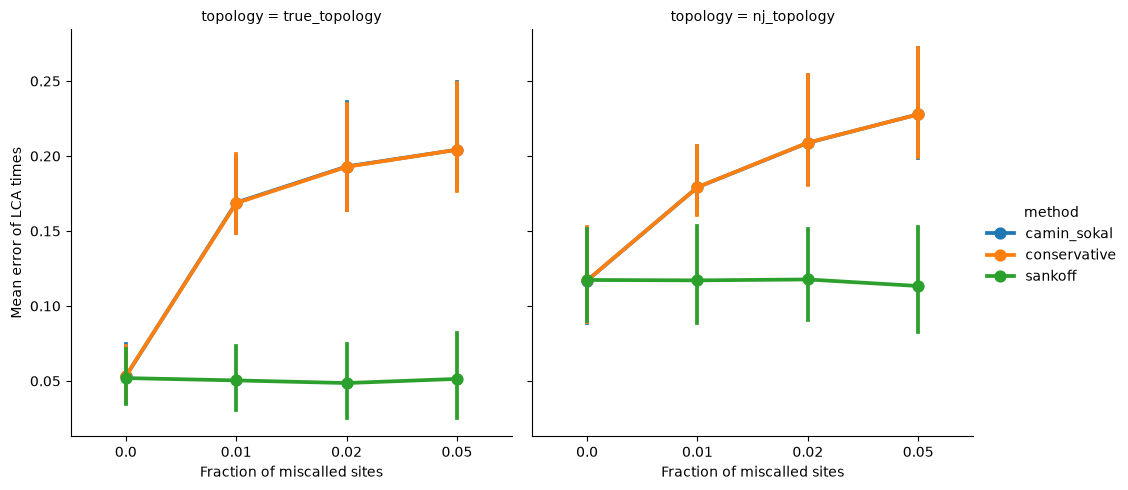

In [13]:
g = sns.catplot(results, x="noise", y="error", hue="method", col="topology", kind="point")
g.set_axis_labels("Fraction of miscalled sites", "Mean error of LCA times");

Without noise, all three methods give the same accuracy. With as little as 1% of miscalled sites,
Camin-Sokal and the conservative method lose much of their accuracy, while Sankoff is barely affected,
on both the true and the reconstructed topology. Because real data always contain some errors, we
recommend `method="sankoff"` before estimating branch lengths.

## Using the times

The estimated times can be used for downstream analyses with
[pycea](https://pycea.readthedocs.io/en/latest/), for example to count lineages over time
({func}`pycea.tl.n_extant`), define clades at a given time ({func}`pycea.tl.clades`) or estimate fitness
({func}`pycea.tl.fitness`). If cells were sampled at different times, pass the sampling times with
`leaf_time_key` so that times are reported in those units (see {func}`cassiopeia.sim.sample_timepoints`
to simulate such data). For an example on real data, see the
[basic tree reconstruction tutorial](reconstruct.ipynb).